# Cognifyz Technologies — Data Science Internship
## Level 1 · Task 1: Data Exploration and Preprocessing

### Objectives
1. Identify the number of rows and columns.
2. Check and handle missing values.
3. Review and convert data types when necessary.
4. Analyze the distribution of **`Aggregate rating`** and check for class imbalance.

**Dataset path:** `../dataset/Dataset.csv`

> Keep the original CSV unchanged. Cleaning and preprocessing will be performed on `df_clean`.

## 1. Import libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset
Expected project structure:

```text
Cognifyz_Internship/
├── Dataset/
│   └── Dataset.csv
└── Level1/
    └── Task1_Data_Exploration.ipynb
```

In [2]:
DATA_PATH = Path("../dataset/Dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place the CSV at Cognifyz_Internship/Dataset/Dataset.csv."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 3. Number of rows and columns

In [3]:
rows, columns = df.shape
print(f"Rows    : {rows:,}")
print(f"Columns : {columns:,}")

display(df.head())

Rows    : 9,551
Columns : 21


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenue, Poblacion, Makati City","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Makati City",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Makati City",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Mandaluyong City",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 4. Inspect columns and data types

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [5]:
data_profile = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Values": df.notna().sum(),
    "Missing Values": df.isna().sum(),
    "Unique Values": df.nunique(dropna=True)
})
display(data_profile)

,Data Type,Non-Null Values,Missing Values,Unique Values
Restaurant ID,int64,9551,0,9551
Restaurant Name,str,9551,0,7446
Country Code,int64,9551,0,15
City,str,9551,0,141
Address,str,9551,0,8918
Locality,str,9551,0,1208
Locality Verbose,str,9551,0,1265
Longitude,float64,9551,0,8120
Latitude,float64,9551,0,8677
Cuisines,str,9542,9,1825


## 5. Missing-value analysis
Calculate missing counts and percentages for every column.

,Missing Values,Missing Percentage (%)
Cuisines,9,0.09


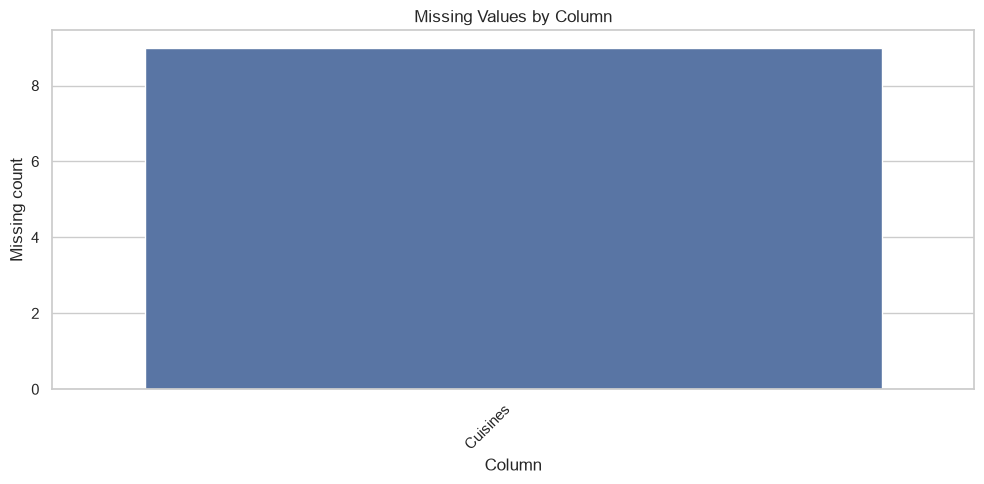

In [6]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Values", ascending=False)

display(missing_summary[missing_summary["Missing Values"] > 0])

missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if len(missing_counts):
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_counts.index, y=missing_counts.values)
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

### Handle missing values

`Cuisines` is a categorical column. Missing cuisine entries will be labelled `Unknown` so those restaurant rows are retained. For any missing `Aggregate rating`, we will not invent a rating; such rows will be excluded from rating-specific analysis only.

In [7]:
df_clean = df.copy()

if "Cuisines" in df_clean.columns:
    df_clean["Cuisines"] = df_clean["Cuisines"].fillna("Unknown")

if "Aggregate rating" in df_clean.columns:
    print("Missing target values before handling:",
          df_clean["Aggregate rating"].isna().sum())

print("Missing values after selected handling:")
display(df_clean.isna().sum().to_frame("Missing Values"))

Missing target values before handling: 0
Missing values after selected handling:


,Missing Values
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,0


## 6. Data type review and conversion
Convert `Aggregate rating` to numeric if needed. Other columns are left in their original types unless a clear conversion is required.

In [8]:
print("Data types before conversion:")
display(df_clean.dtypes.astype(str).to_frame("Data Type"))

if "Aggregate rating" in df_clean.columns:
    df_clean["Aggregate rating"] = pd.to_numeric(
        df_clean["Aggregate rating"], errors="coerce"
    )

print("Data types after review:")
display(df_clean.dtypes.astype(str).to_frame("Data Type"))

Data types before conversion:


,Data Type
Restaurant ID,int64
Restaurant Name,str
Country Code,int64
City,str
Address,str
Locality,str
Locality Verbose,str
Longitude,float64
Latitude,float64
Cuisines,str


Data types after review:


,Data Type
Restaurant ID,int64
Restaurant Name,str
Country Code,int64
City,str
Address,str
Locality,str
Locality Verbose,str
Longitude,float64
Latitude,float64
Cuisines,str


## 7. Analyze `Aggregate rating`
Inspect descriptive statistics, rating counts, and percentages. A rating of `0` may represent a restaurant that has not received a rating in this dataset, so interpret it separately rather than assuming it means a poor rating.

In [9]:
if "Aggregate rating" not in df_clean.columns:
    raise KeyError("Expected target column 'Aggregate rating' was not found.")

target = df_clean["Aggregate rating"].dropna()

display(target.describe().to_frame("Aggregate rating"))

rating_counts = target.value_counts().sort_index()
display(rating_counts.rename("Restaurant Count").to_frame())

,Aggregate rating
count,9551.000000
mean,2.666370
std,1.516378
min,0.000000
25%,2.500000
50%,3.200000
75%,3.700000
max,4.900000


,Restaurant Count
Aggregate rating,
0.0,2148
1.8,1
1.9,2
2.0,7
2.1,15
2.2,27
2.3,47
2.4,87
2.5,110


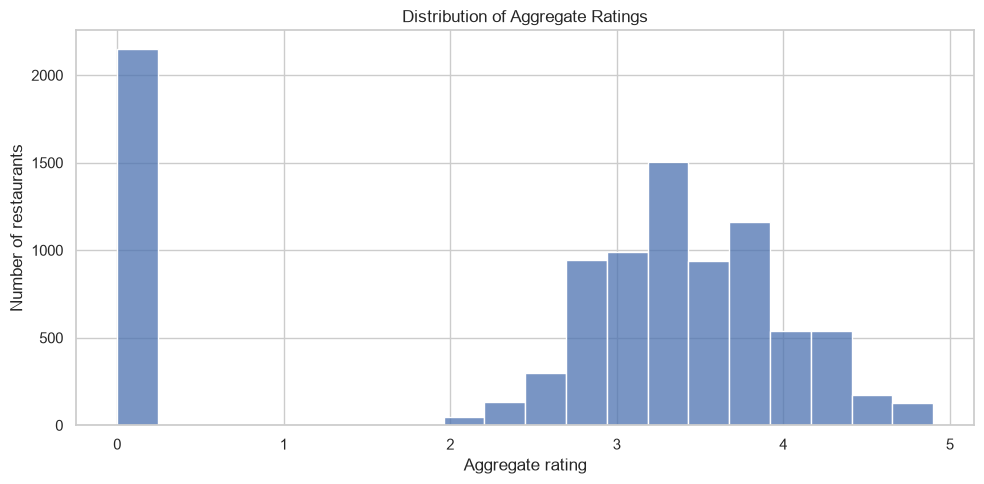

In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(target, bins=20)
plt.title("Distribution of Aggregate Ratings")
plt.xlabel("Aggregate rating")
plt.ylabel("Number of restaurants")
plt.tight_layout()
plt.show()

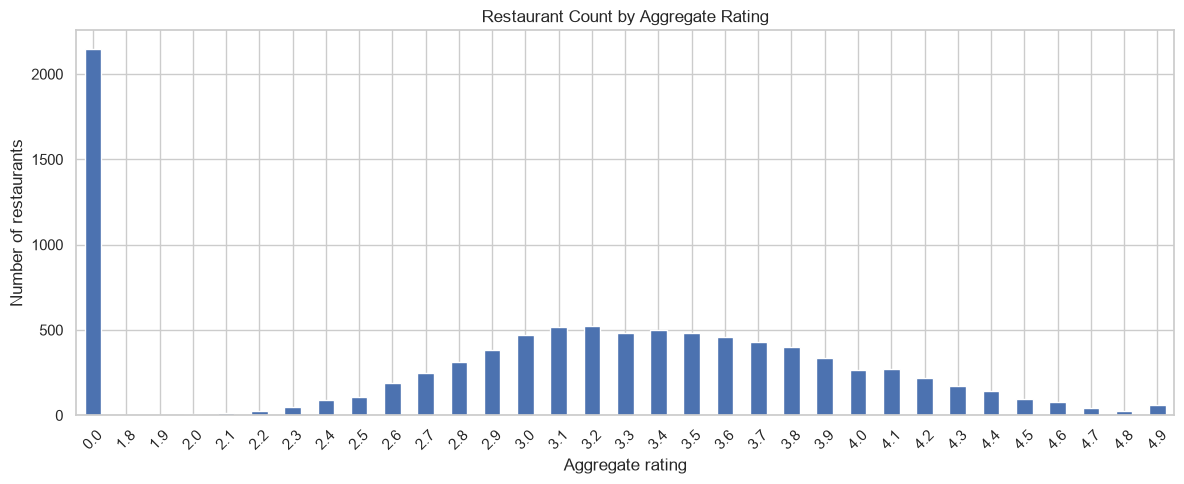

In [11]:
plt.figure(figsize=(12, 5))
rating_counts.plot(kind="bar")
plt.title("Restaurant Count by Aggregate Rating")
plt.xlabel("Aggregate rating")
plt.ylabel("Number of restaurants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Rating distribution and class-imbalance check
Compare the number and percentage of records for each distinct rating. This is a descriptive imbalance check; resampling is not automatically required for this exploration task.

In [12]:
rating_distribution = pd.DataFrame({
    "Count": rating_counts,
    "Percentage (%)": (rating_counts / rating_counts.sum() * 100).round(2)
}).sort_values("Count", ascending=False)

display(rating_distribution)

if not rating_distribution.empty:
    print(f"Most frequent rating: {rating_distribution['Count'].idxmax()}")
    print(f"Least frequent rating: {rating_distribution['Count'].idxmin()}")
    print(f"Largest class share: {rating_distribution['Percentage (%)'].max():.2f}%")
    print(f"Smallest class share: {rating_distribution['Percentage (%)'].min():.2f}%")

,Count,Percentage (%)
Aggregate rating,,
0.0,2148,22.49
3.2,522,5.47
3.1,519,5.43
3.4,498,5.21
3.3,483,5.06
3.5,480,5.03
3.0,468,4.90
3.6,458,4.80
3.7,427,4.47


Most frequent rating: 0.0
Least frequent rating: 1.8
Largest class share: 22.49%
Smallest class share: 0.01%


## 9. Final data-quality check

In [13]:
print(f"Original dataset shape : {df.shape}")
print(f"Working dataset shape  : {df_clean.shape}")
print(f"Row count preserved    : {len(df) == len(df_clean)}")

display(df_clean.head())
display(df_clean.isna().sum().to_frame("Remaining Missing Values"))

Original dataset shape : (9551, 21)
Working dataset shape  : (9551, 21)
Row count preserved    : True


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenue, Poblacion, Makati City","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Makati City",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Makati City",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Mandaluyong City",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


,Remaining Missing Values
Restaurant ID,0
Restaurant Name,0
Country Code,0
City,0
Address,0
Locality,0
Locality Verbose,0
Longitude,0
Latitude,0
Cuisines,0


## 10. Conclusion

After running all cells, use the actual outputs above to write the final findings:

- **Dataset dimensions:** record the row and column counts from Section 3.
- **Missing values:** state which columns contained missing data and how they were handled.
- **Data types:** mention any conversion performed in Section 6.
- **Rating distribution:** describe the most and least frequent rating values using Section 8.
- **Class imbalance:** use the observed counts and percentages to support the conclusion.
- **Data integrity:** confirm whether the original row count was preserved.

Do not report conclusions until you have run the notebook and reviewed its outputs.